# **Project Name - Play Store App Review Analysis**

##### **Project Type - EDA**
##### **Contribution - Individual**
##### **Name - Add your name**

# **Project Summary -**

This project explores the Google Play Store apps dataset and the User Reviews dataset. The aim is to understand the apps in the available data and find patterns in their ratings, installs, prices, sizes, and customer feedback. These patterns can help app developers think about app quality, pricing, and customer satisfaction. The project uses Python, Pandas, NumPy, Matplotlib, and Seaborn. It is designed to run in Google Colab, with simple code and explanations that are easy to follow.

The first dataset contains information about apps, such as their names, categories, ratings, number of reviews, installation counts, prices, and content ratings. The second dataset contains translated customer reviews and their sentiment labels. It also includes sentiment polarity and subjectivity scores. Together, the files provide two useful views: the characteristics of listed apps and the opinions found in the supplied reviews. The review total in the apps file is different from the number of text reviews in the second file.

The analysis begins by looking at the first and last rows of each dataset. The number of rows and columns, column names, data types, summary statistics, missing values, and duplicate rows are checked. These steps help explain what the files contain before any conclusions are made. A short data dictionary explains the important columns. The original datasets are kept separately so that the cleaning steps can be followed and compared with the starting data.

The cleaning process removes duplicate records and a malformed app record. Reviews, installs, prices, and sizes are converted into numerical values where possible. Repeated app names are handled by keeping the record with the largest review count. Missing ratings are left missing instead of assigning a rating that was not observed. Apps with missing ratings can still be used in charts about categories or pricing. Device-dependent sizes are also left missing. Rows without usable review text or sentiment are excluded from sentiment analysis. Very large but valid values are retained because popular apps and expensive apps can be real observations.

The visual analysis moves from simple distributions to comparisons and relationships. Twenty charts cover ratings, app categories, free and paid apps, content ratings, installs, prices, sizes, review counts, and sentiment. Histograms show distributions, bar charts compare groups, scatter plots show relationships, and box plots compare numerical spread. A pie chart shows pricing composition, while a heatmap summarises numerical correlations. Every chart has a short explanation of why it was chosen, what it shows, and how the observation could help a business.

The final section connects the findings to practical suggestions. Developers can compare their app with similar apps, inspect negative reviews, and investigate quality problems. Pricing decisions need information about revenue and customer behaviour in addition to downloads. The supplied data cannot measure retention, profit, or current market conditions. Installation values are recorded thresholds rather than exact active-user counts. The conclusions therefore describe this dataset and do not prove that one feature causes success. Future work could add recent data, review topics, revenue, and retention measures, or present the results in a simple dashboard.

# **GitHub Link -**

Add your GitHub project link here.

# **Problem Statement**

Study the Play Store apps and user reviews to understand patterns in app ratings, popularity and customer feedback.

#### **Define Your Business Objective?**

Help developers understand which app characteristics are associated with installs and ratings, and use customer feedback to identify areas worth improving.

# **General Guidelines**

Use clear, commented code. Explain why each chart was selected, what it shows and how the finding can help a business. This notebook includes 20 charts and more than five chart types.

### How to run
Upload both CSV files to the Google Colab **Files** panel. Then select **Runtime > Run all**. Keep the original filenames. If running locally, keep both CSV files in the same folder as this notebook.

# ***Let's Begin!***

# 1. Know Your Data
### Import Libraries

In [1]:
# Import the four main libraries used in this project.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

### Load the Datasets

In [2]:
# Read the files uploaded to Colab or saved beside the notebook.
Data = pd.read_csv('Play Store Data.csv')
Review = pd.read_csv('User Reviews.csv')

### First and Last Rows

In [3]:
# Check a few records from both ends of each dataset.
display(Data.head())
display(Data.tail())
display(Review.head())
display(Review.tail())

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1.0,4.1 and up
10838,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,"January 20, 2017",1.0,2.2 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,Varies with device
10840,iHoroscope - 2018 Daily Horoscope & Astrology,LIFESTYLE,4.5,398307,19M,"10,000,000+",Free,0,Everyone,Lifestyle,"July 25, 2018",Varies with device,Varies with device


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
64290,Houzz Interior Design Ideas,NaN,NaN,NaN,NaN
64291,Houzz Interior Design Ideas,NaN,NaN,NaN,NaN
64292,Houzz Interior Design Ideas,NaN,NaN,NaN,NaN
64293,Houzz Interior Design Ideas,NaN,NaN,NaN,NaN
64294,Houzz Interior Design Ideas,NaN,NaN,NaN,NaN


### Rows, Columns and Data Types

In [4]:
# Check the size, columns and data types of both files.
print('Apps dataset shape:', Data.shape)
print('Reviews dataset shape:', Review.shape)
print('Apps columns:', Data.columns.tolist())
print('Reviews columns:', Review.columns.tolist())
Data.info()
Review.info()

Apps dataset shape: (10841, 13)
Reviews dataset shape: (64295, 5)
Apps columns: ['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']
Reviews columns: ['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']
<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10

### Summary, Duplicate Rows and Missing Values

In [5]:
# Review summary statistics and basic data-quality issues.
display(Data.describe(include='all').T)
display(Review.describe(include='all').T)
print('Duplicate app rows:', Data.duplicated().sum())
print('Duplicate review rows:', Review.duplicated().sum())
display(Data.isnull().sum().to_frame('Missing app values'))
display(Review.isnull().sum().to_frame('Missing review values'))

Duplicate app rows: 483
Duplicate review rows: 33616


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
App,10841,9660,ROBLOX,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,10841,34,FAMILY,1972,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9367.0,NaN,NaN,NaN,4.193338,0.537431,1.0,4.0,4.3,4.5,19.0
Reviews,10841,6002,0,596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,10841,462,Varies with device,1695,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Installs,10841,22,"1,000,000+",1579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10840,3,Free,10039,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,10841,93,0,10040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Content Rating,10840,6,Everyone,8714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genres,10841,120,Tools,842,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
App,64295,1074,Angry Birds Classic,320,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Translated_Review,37427,27994,Good,247,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sentiment,37432,3,Positive,23998,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sentiment_Polarity,37432.0,NaN,NaN,NaN,0.182146,0.351301,-1.0,0.0,0.15,0.4,1.0
Sentiment_Subjectivity,37432.0,NaN,NaN,NaN,0.492704,0.259949,0.0,0.357143,0.514286,0.65,1.0


,Missing app values
App,0
Category,0
Rating,1474
Reviews,0
Size,0
Installs,0
Type,1
Price,0
Content Rating,1
Genres,0


,Missing review values
App,0
Translated_Review,26868
Sentiment,26863
Sentiment_Polarity,26863
Sentiment_Subjectivity,26863


### What did you learn about the datasets?
The apps file contains app details, while the reviews file contains customer feedback. Some numbers, such as installs and prices, are stored as text. There are missing values and repeated records, so cleaning is needed before making charts.

# 2. Understanding Your Variables
| Column | Simple meaning |
|---|---|
| App | Name of the app |
| Category | Main app category |
| Rating | Average user rating, from 1 to 5 |
| Reviews | Number of reviews recorded in the apps file |
| Size | App file size |
| Installs | Recorded download threshold, such as 10,000+ |
| Type | Free or Paid |
| Price | Listed price in US dollars |
| Content Rating | Intended content audience |
| Genres | Additional app genres |
| Last Updated | Recorded date of the last update |
| Current Ver | App version |
| Android Ver | Required Android version |
| Translated_Review | Customer review translated into English |
| Sentiment | Positive, Negative or Neutral feedback |
| Sentiment_Polarity | Sentiment score from -1 to 1 |
| Sentiment_Subjectivity | Opinion-based score from 0 to 1 |

In [6]:
# Look at the main category values.
print('Categories:', Data['Category'].unique())
print('Pricing types:', Data['Type'].unique())
print('Content ratings:', Data['Content Rating'].unique())
print('Sentiments:', Review['Sentiment'].unique())

Categories: <StringArray>
[     'ART_AND_DESIGN',   'AUTO_AND_VEHICLES',              'BEAUTY',
 'BOOKS_AND_REFERENCE',            'BUSINESS',              'COMICS',
       'COMMUNICATION',              'DATING',           'EDUCATION',
       'ENTERTAINMENT',              'EVENTS',             'FINANCE',
      'FOOD_AND_DRINK',  'HEALTH_AND_FITNESS',      'HOUSE_AND_HOME',
  'LIBRARIES_AND_DEMO',           'LIFESTYLE',                'GAME',
              'FAMILY',             'MEDICAL',              'SOCIAL',
            'SHOPPING',         'PHOTOGRAPHY',              'SPORTS',
    'TRAVEL_AND_LOCAL',               'TOOLS',     'PERSONALIZATION',
        'PRODUCTIVITY',           'PARENTING',             'WEATHER',
       'VIDEO_PLAYERS',  'NEWS_AND_MAGAZINES', 'MAPS_AND_NAVIGATION',
                 '1.9']
Length: 34, dtype: str
Pricing types: <StringArray>
['Free', 'Paid', nan, '0']
Length: 4, dtype: str
Content ratings: <StringArray>
[       'Everyone',            'Teen',    'Every

# 3. Data Wrangling
We will clean text-formatted numbers, remove repeated records and keep missing values only where they do not affect a calculation.

In [7]:
# Keep the original data for reference.
Original_Data = Data.copy()
Original_Review = Review.copy()

# Remove exact duplicate rows and the malformed category record.
Data = Data.drop_duplicates().copy()
Data = Data[Data['Category'] != '1.9'].copy()

# Convert numerical columns from text to numbers.
Data['Reviews'] = pd.to_numeric(Data['Reviews'], errors='coerce')
Data['Installs'] = Data['Installs'].str.replace(',', '', regex=False).str.replace('+', '', regex=False)
Data['Installs'] = pd.to_numeric(Data['Installs'], errors='coerce')
Data['Price'] = Data['Price'].astype(str).str.replace('$', '', regex=False)
Data['Price'] = pd.to_numeric(Data['Price'], errors='coerce')
Data['Rating'] = pd.to_numeric(Data['Rating'], errors='coerce')

# Convert sizes to MB. A value ending in k is divided by 1024.
Size_Text = Data['Size'].astype(str)
Data['Size_MB'] = pd.to_numeric(Size_Text.str.replace('M', '', regex=False).str.replace('k', '', regex=False), errors='coerce')
Data.loc[Size_Text.str.endswith('k'), 'Size_MB'] = Data.loc[Size_Text.str.endswith('k'), 'Size_MB'] / 1024

# Remove unusable essential values and keep valid ratings only.
Data = Data.dropna(subset=['App', 'Category', 'Reviews', 'Installs', 'Price'])
Data = Data[(Data['Reviews'] >= 0) & (Data['Installs'] >= 0) & (Data['Price'] >= 0)].copy()
Data.loc[~Data['Rating'].between(1, 5), 'Rating'] = np.nan
Data.loc[Data['Size_MB'] <= 0, 'Size_MB'] = np.nan

# Use the price to fill the few missing pricing types.
Data.loc[Data['Type'].isna() & (Data['Price'] == 0), 'Type'] = 'Free'
Data.loc[Data['Type'].isna() & (Data['Price'] > 0), 'Type'] = 'Paid'

# Keep one record per app: the record with the largest review count.
Data = Data.sort_values('Reviews', ascending=False, kind='stable')
Data = Data.drop_duplicates(subset='App').reset_index(drop=True)

# Keep usable reviews; do not create missing sentiment labels.
Review = Review.drop_duplicates().copy()
Review = Review.dropna(subset=['App', 'Translated_Review', 'Sentiment'])
Review = Review[Review['Sentiment'].isin(['Positive', 'Negative', 'Neutral'])].copy()
Review['Sentiment_Polarity'] = pd.to_numeric(Review['Sentiment_Polarity'], errors='coerce')
Review['Sentiment_Subjectivity'] = pd.to_numeric(Review['Sentiment_Subjectivity'], errors='coerce')
Review.loc[~Review['Sentiment_Polarity'].between(-1, 1), 'Sentiment_Polarity'] = np.nan
Review.loc[~Review['Sentiment_Subjectivity'].between(0, 1), 'Sentiment_Subjectivity'] = np.nan

print('App rows before / after cleaning:', len(Original_Data), '/', len(Data))
print('Review rows before / after cleaning:', len(Original_Review), '/', len(Review))
display(Data.isnull().sum().to_frame('Missing after cleaning'))

App rows before / after cleaning: 10841 / 9659
Review rows before / after cleaning: 64295 / 29692


,Missing after cleaning
App,0
Category,0
Rating,1463
Reviews,0
Size,0
Installs,0
Type,0
Price,0
Content Rating,0
Genres,0


### Why were missing values handled this way?
- **Rating:** left missing because a guessed rating could change the findings. Charts about ratings use available values.
- **Size:** device-dependent size is unknown, so only size charts exclude it.
- **Type:** a zero price means Free; a positive price means Paid.
- **Reviews:** rows without text or a valid sentiment label cannot support sentiment charts.
- **Other columns:** version and update fields are not needed for the charts, so their missing values are left unchanged.

### How were outliers handled?
We keep valid large apps and high prices. A popular app is not an error just because it has many downloads. Medians are used for group install comparisons. A few charts use a log scale to make very large differences easier to see. On a log10 scale, 1 means 10 and 2 means 100.

Repeated review rows are removed as possible duplicates. Without review IDs, some identical reviews might be from different users, so this is a limitation.

In [8]:
# Inspect unusually large values instead of deleting them automatically.
display(Data[['Rating', 'Reviews', 'Installs', 'Size_MB', 'Price']].describe())
display(Data.nlargest(5, 'Price')[['App', 'Price', 'Installs']])

,Rating,Reviews,Installs,Size_MB,Price
count,8196.000000,9.659000e+03,9.659000e+03,8431.000000,9659.000000
mean,4.173267,2.168041e+05,7.798170e+06,20.398075,1.097231
std,0.536253,1.831430e+06,5.376973e+07,21.828959,16.851618
min,1.000000,0.000000e+00,0.000000e+00,0.008301,0.000000
25%,4.000000,2.500000e+01,1.000000e+03,4.600000,0.000000
50%,4.300000,9.690000e+02,1.000000e+05,12.000000,0.000000
75%,4.500000,2.945350e+04,1.000000e+06,28.000000,0.000000
max,5.000000,7.815831e+07,1.000000e+09,100.000000,400.000000


,App,Price,Installs
5646,I'm Rich - Trump Edition,400.00,10000
3986,I am rich,399.99,100000
4441,I Am Rich Premium,399.99,50000
4914,I am Rich Plus,399.99,10000
5031,💎 I'm rich,399.99,10000


# 4. Data Visualisation and Storytelling
We first look at single columns, then compare two columns, and finally use a correlation heatmap. Each chart answers one question.

## Chart 1 - Distribution of App Ratings
**Analysis:** Univariate

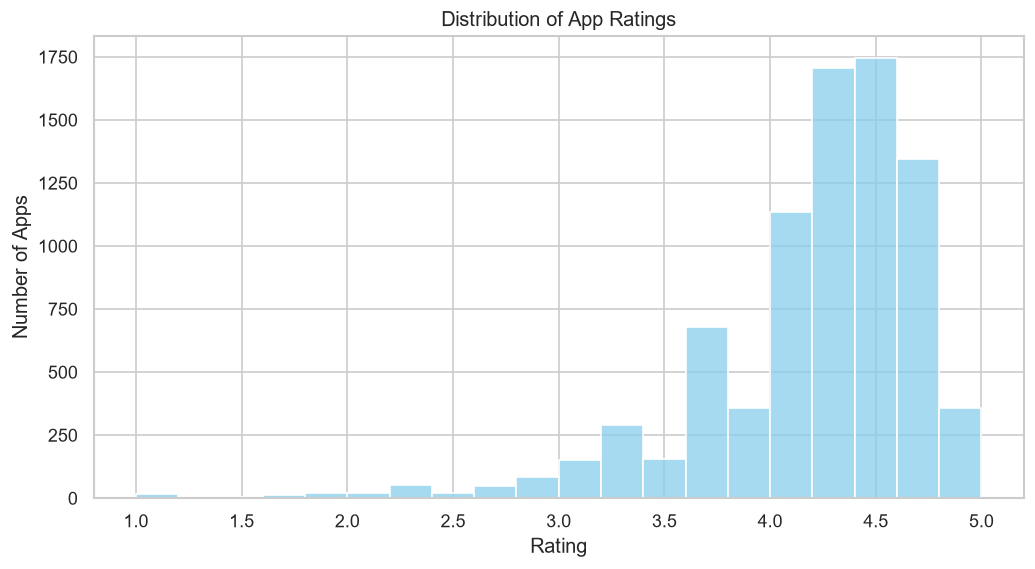

In [9]:
# Plot available ratings.
sns.histplot(Data['Rating'].dropna(), bins=20, color='skyblue')
plt.title('Distribution of App Ratings')
plt.xlabel('Rating'); plt.ylabel('Number of Apps')
plt.show()

**1. Why this chart?** A histogram shows which ratings are common.

**2. What did we find?** The median available rating is 4.3. About 76.7% of rated apps have a rating of 4 or more.

**3. Business impact:** Compare app satisfaction with similar apps. Ratings alone do not measure business success.

## Chart 2 - Top 10 App Categories
**Analysis:** Univariate

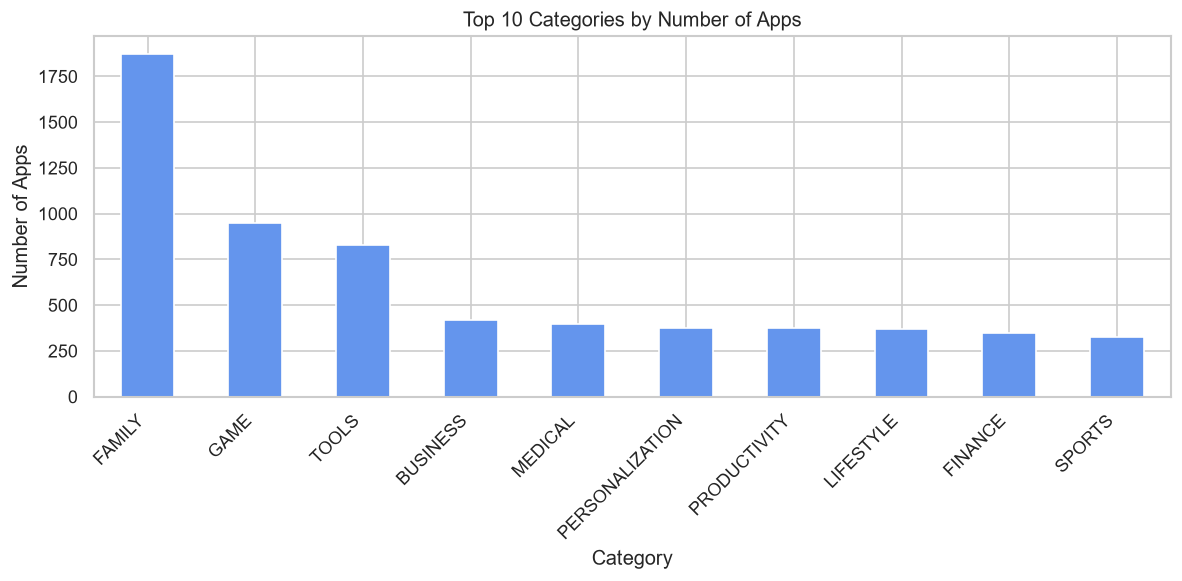

In [10]:
# Count apps in the ten largest categories.
Data['Category'].value_counts().head(10).plot(kind='bar', color='cornflowerblue')
plt.title('Top 10 Categories by Number of Apps')
plt.xlabel('Category'); plt.ylabel('Number of Apps')
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
plt.show()

**1. Why this chart?** A bar chart compares the number of apps in different categories.

**2. What did we find?** FAMILY has the most apps in this dataset (1,874), followed by GAME.

**3. Business impact:** These counts show the available sample. More apps do not automatically mean higher demand.

## Chart 3 - Free and Paid Apps
**Analysis:** Univariate

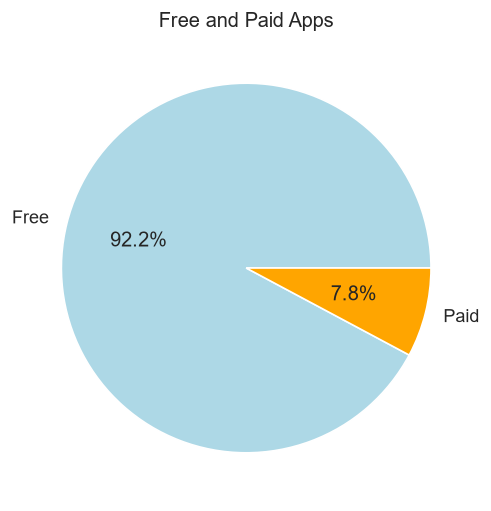

In [11]:
# Compare the share of free and paid apps.
Data['Type'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['lightblue', 'orange'])
plt.title('Free and Paid Apps'); plt.ylabel('')
plt.show()

**1. Why this chart?** A pie chart shows the share of each pricing type.

**2. What did we find?** 92.2% of apps in the cleaned dataset are free.

**3. Business impact:** Free listings are common, but choosing a pricing model also needs revenue and customer data.

## Chart 4 - Content Ratings
**Analysis:** Univariate

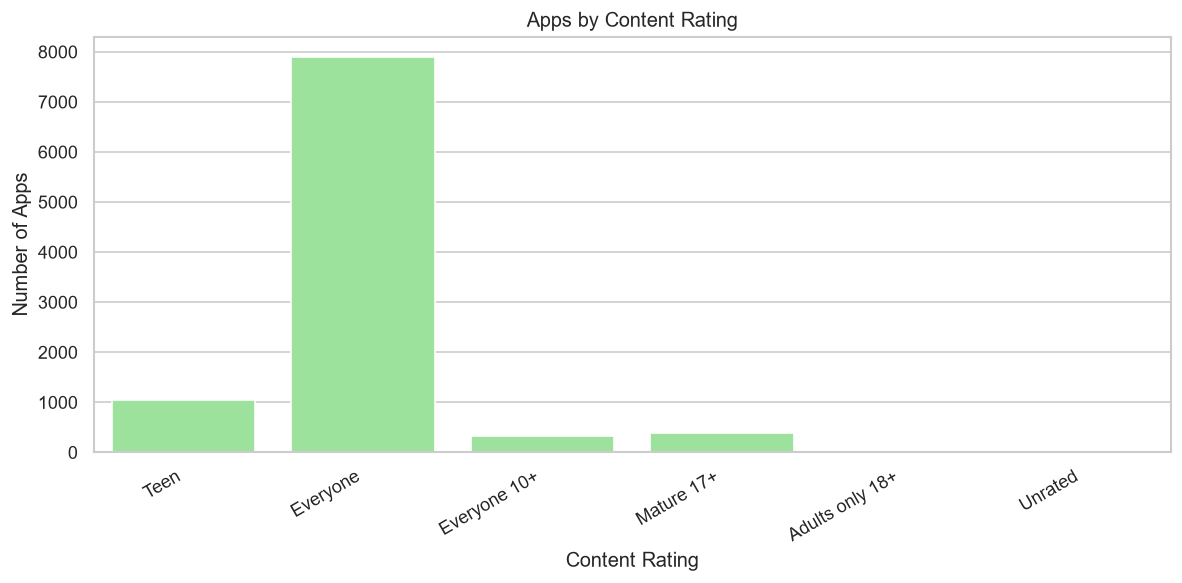

In [12]:
# Count apps by intended content audience.
sns.countplot(data=Data, x='Content Rating', color='lightgreen')
plt.title('Apps by Content Rating')
plt.xlabel('Content Rating'); plt.ylabel('Number of Apps')
plt.xticks(rotation=30, ha='right'); plt.tight_layout()
plt.show()

**1. Why this chart?** A count plot compares audience classifications.

**2. What did we find?** The most common content classification is Everyone.

**3. Business impact:** This describes intended content audiences, not actual user ages. Choose a classification that fits the content.

## Chart 5 - App Sizes
**Analysis:** Univariate

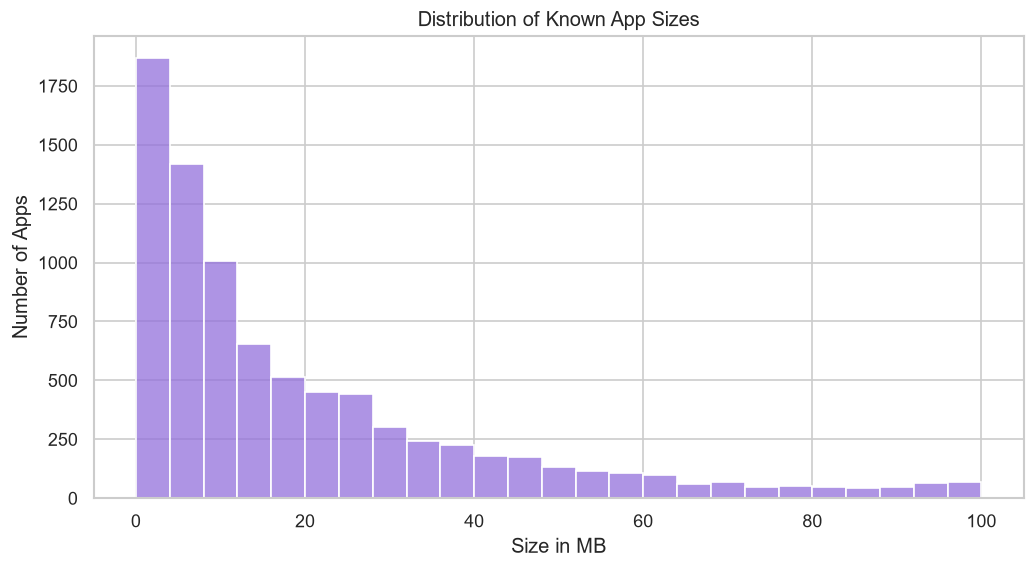

In [13]:
# Exclude unknown sizes only for this chart.
sns.histplot(Data['Size_MB'].dropna(), bins=25, color='mediumpurple')
plt.title('Distribution of Known App Sizes')
plt.xlabel('Size in MB'); plt.ylabel('Number of Apps')
plt.show()

**1. Why this chart?** A histogram shows the distribution of fixed app sizes.

**2. What did we find?** The median known size is 12.0 MB. Size is known for 8,431 apps.

**3. Business impact:** Package size can be reviewed for efficiency. Device-dependent sizes are not included here.

## Chart 6 - Customer Review Sentiment
**Analysis:** Univariate

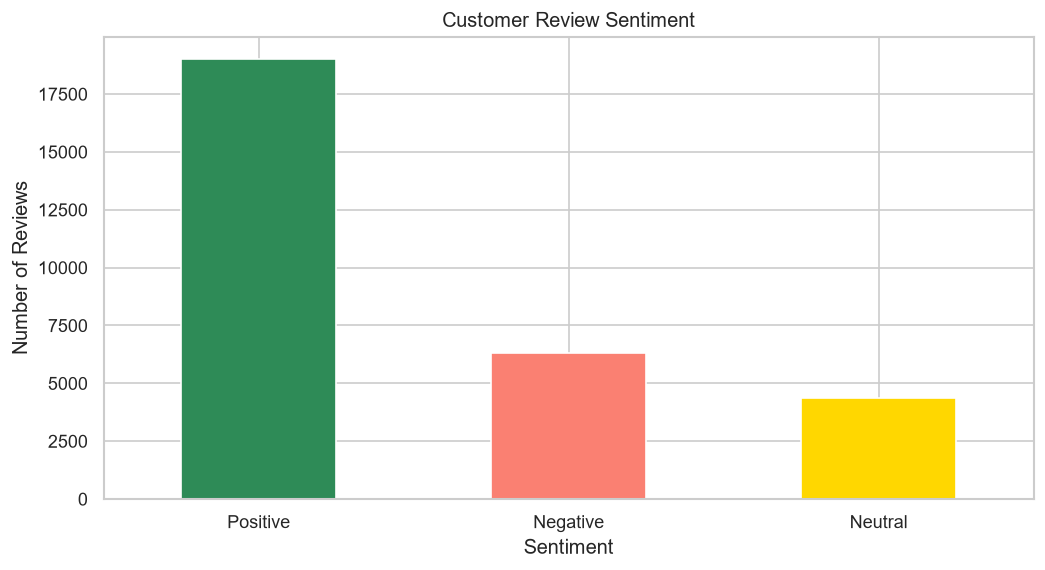

In [14]:
# Use sentiment labels already supplied in the review dataset.
Review['Sentiment'].value_counts().plot(kind='bar', color=['seagreen', 'salmon', 'gold'])
plt.title('Customer Review Sentiment')
plt.xlabel('Sentiment'); plt.ylabel('Number of Reviews')
plt.xticks(rotation=0); plt.show()

**1. Why this chart?** A bar chart compares positive, negative and neutral review counts.

**2. What did we find?** Positive is the largest group. Positive reviews account for 64.0% of usable reviews.

**3. Business impact:** Read negative feedback to identify real issues. These supplied reviews may not represent all users.

## Chart 7 - Installation Distribution
**Analysis:** Univariate

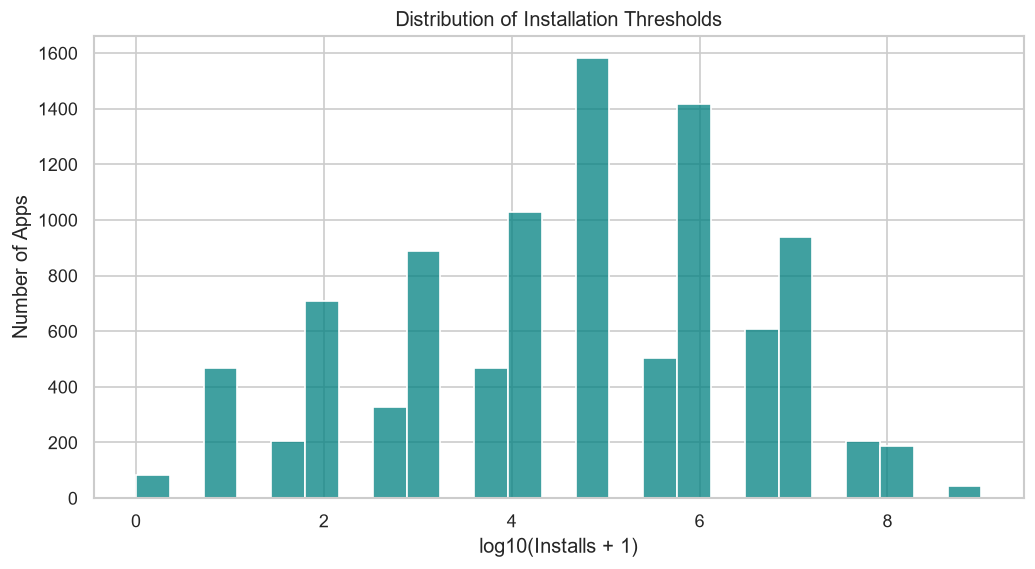

In [15]:
# Log10 reduces the visual effect of very large download thresholds.
sns.histplot(np.log10(Data['Installs'] + 1), bins=25, color='teal')
plt.title('Distribution of Installation Thresholds')
plt.xlabel('log10(Installs + 1)'); plt.ylabel('Number of Apps')
plt.show()

**1. Why this chart?** A histogram shows reach levels. Log10 makes small and large values visible together.

**2. What did we find?** The median recorded installation lower bound is 100,000.

**3. Business impact:** Use this as a rough reach benchmark. Install values are thresholds, not exact active-user counts.

## Chart 8 - Paid App Prices
**Analysis:** Univariate

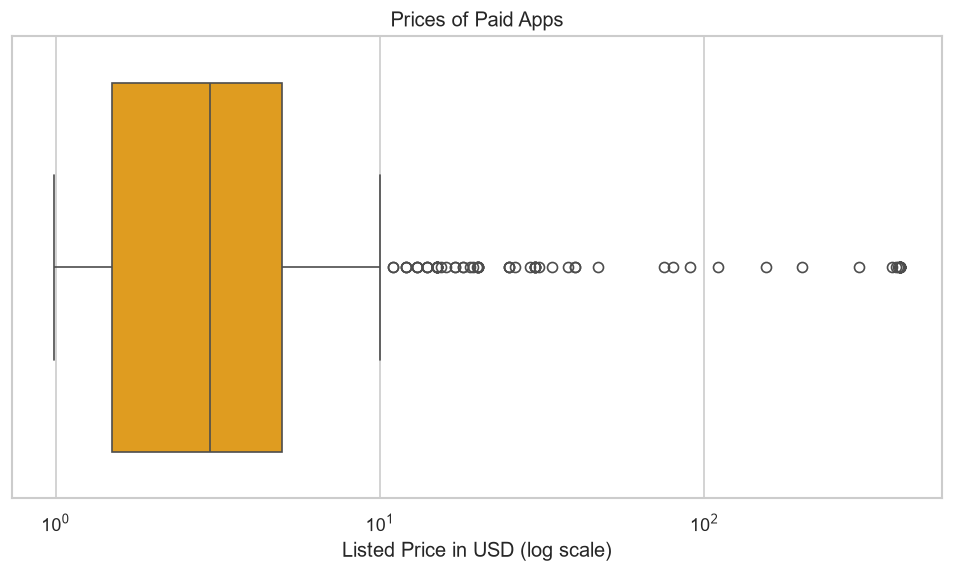

In [16]:
# Show only positive prices and use a log scale for readability.
Paid_Apps = Data[Data['Price'] > 0]
sns.boxplot(x=Paid_Apps['Price'], color='orange')
plt.xscale('log')
plt.title('Prices of Paid Apps')
plt.xlabel('Listed Price in USD (log scale)')
plt.show()

**1. Why this chart?** A box plot shows the middle price and unusual high values.

**2. What did we find?** The median positive price is $2.99. Very expensive listings also exist.

**3. Business impact:** Compare typical prices rather than copying extreme prices. Listing price does not reveal actual revenue.

## Chart 9 - Average Rating by Category
**Analysis:** Bivariate

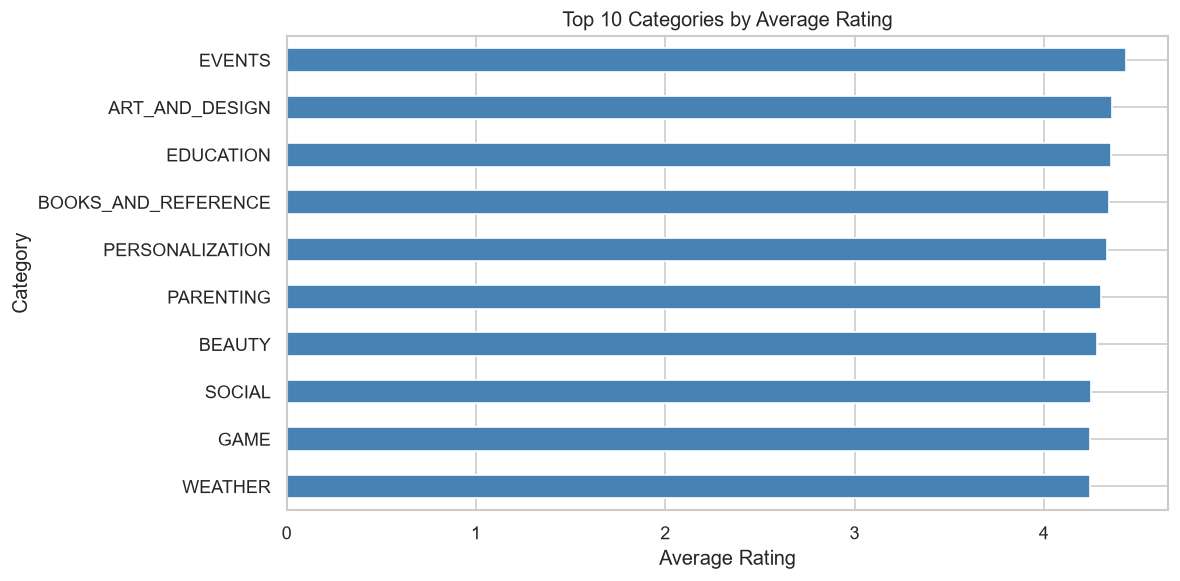

,count,mean
Category,,
EVENTS,45,4.435556
ART_AND_DESIGN,59,4.359322
EDUCATION,106,4.354717
BOOKS_AND_REFERENCE,169,4.344970
PERSONALIZATION,298,4.332215
PARENTING,50,4.300000
BEAUTY,42,4.278571
SOCIAL,203,4.247291
GAME,899,4.244605


In [17]:
# Compare average observed ratings in the top ten categories.
Category_Rating = Data.groupby('Category')['Rating'].mean().sort_values(ascending=False).head(10)
Category_Rating.sort_values().plot(kind='barh', color='steelblue')
plt.title('Top 10 Categories by Average Rating')
plt.xlabel('Average Rating'); plt.ylabel('Category')
plt.tight_layout(); plt.show()
# Show counts so small categories are not mistaken for strong evidence.
display(Data.groupby('Category')['Rating'].agg(['count', 'mean']).loc[Category_Rating.index])

**1. Why this chart?** A horizontal bar chart makes category averages easy to compare.

**2. What did we find?** EVENTS has the highest average rating (4.44) in this cleaned sample.

**3. Business impact:** Compare category ratings with their sample counts. A high average does not guarantee success for a new app.

## Chart 10 - Ratings of Free and Paid Apps
**Analysis:** Bivariate

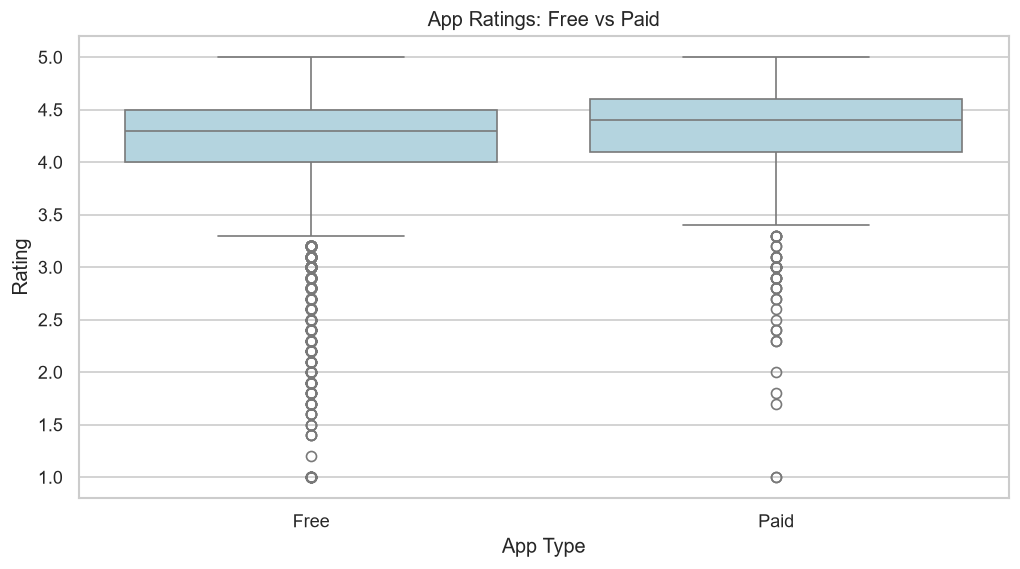

In [18]:
# Compare ratings between the two pricing types.
sns.boxplot(data=Data, x='Type', y='Rating', order=['Free', 'Paid'], color='lightblue')
plt.title('App Ratings: Free vs Paid')
plt.xlabel('App Type'); plt.ylabel('Rating')
plt.show()

**1. Why this chart?** A box plot compares the typical rating and spread.

**2. What did we find?** Median ratings are 4.3 for free apps and 4.4 for paid apps.

**3. Business impact:** Users can rate both free and paid apps highly. The chart does not prove that changing price changes satisfaction.

## Chart 11 - Reviews and Installs
**Analysis:** Bivariate

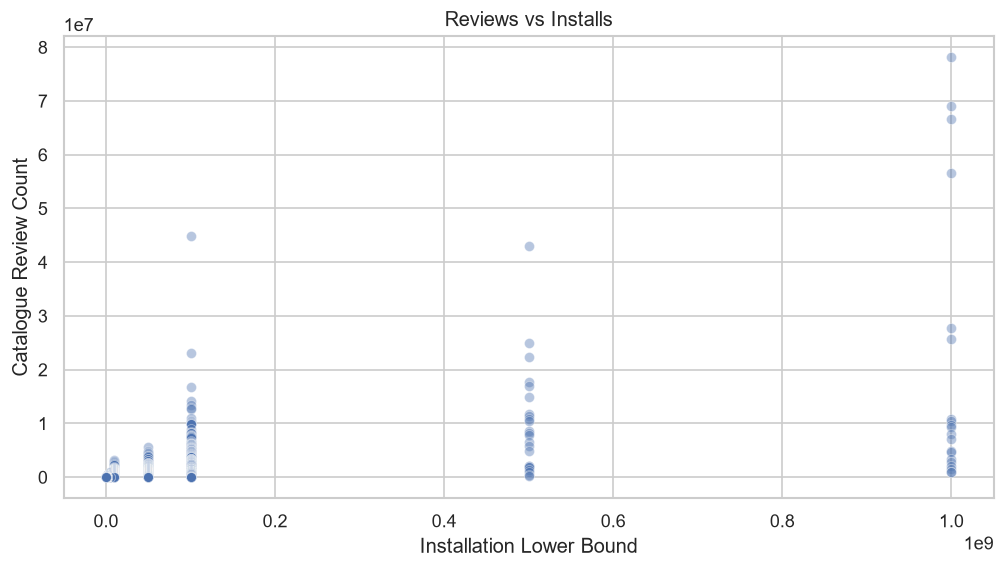

In [19]:
# Compare catalogue review totals and installation thresholds.
sns.scatterplot(data=Data, x='Installs', y='Reviews', alpha=0.4)
plt.title('Reviews vs Installs')
plt.xlabel('Installation Lower Bound'); plt.ylabel('Catalogue Review Count')
plt.show()

**1. Why this chart?** A scatter plot shows whether two numerical measures move together.

**2. What did we find?** The Pearson correlation between reviews and installs is 0.63. Larger apps often have more reviews.

**3. Business impact:** More downloads create more opportunities for reviews. This does not prove reviews cause growth.

## Chart 12 - Ratings and Installs
**Analysis:** Bivariate

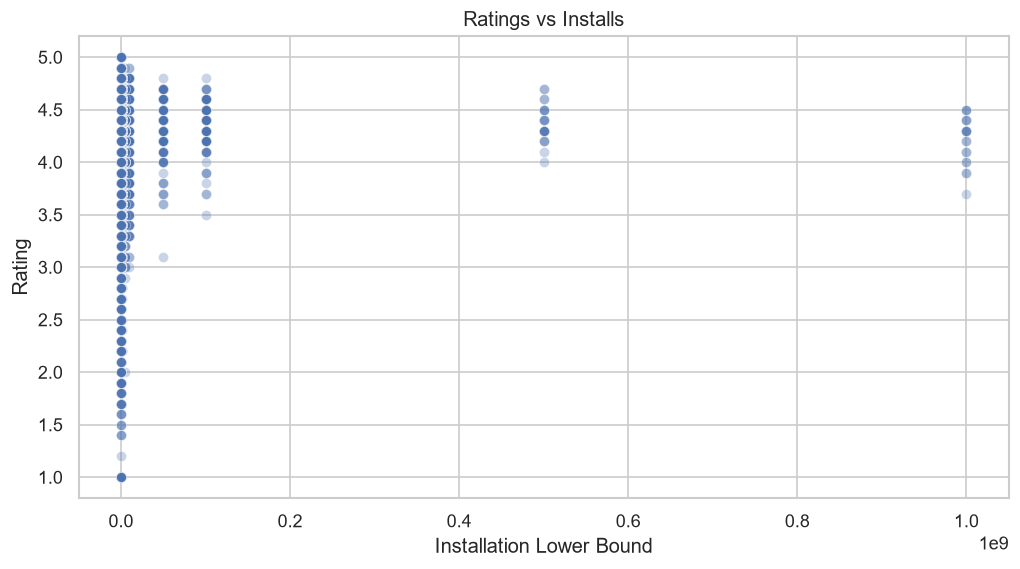

In [20]:
# Compare app ratings with installation thresholds.
sns.scatterplot(data=Data, x='Installs', y='Rating', alpha=0.3)
plt.title('Ratings vs Installs')
plt.xlabel('Installation Lower Bound'); plt.ylabel('Rating')
plt.show()

**1. Why this chart?** A scatter plot shows how ratings vary across reach levels.

**2. What did we find?** The Pearson correlation is 0.04. A high rating alone is not a strong explanation of reach in this snapshot.

**3. Business impact:** Track satisfaction and downloads separately. Other factors such as app age and promotion are not available here.

## Chart 13 - Price and Rating
**Analysis:** Bivariate

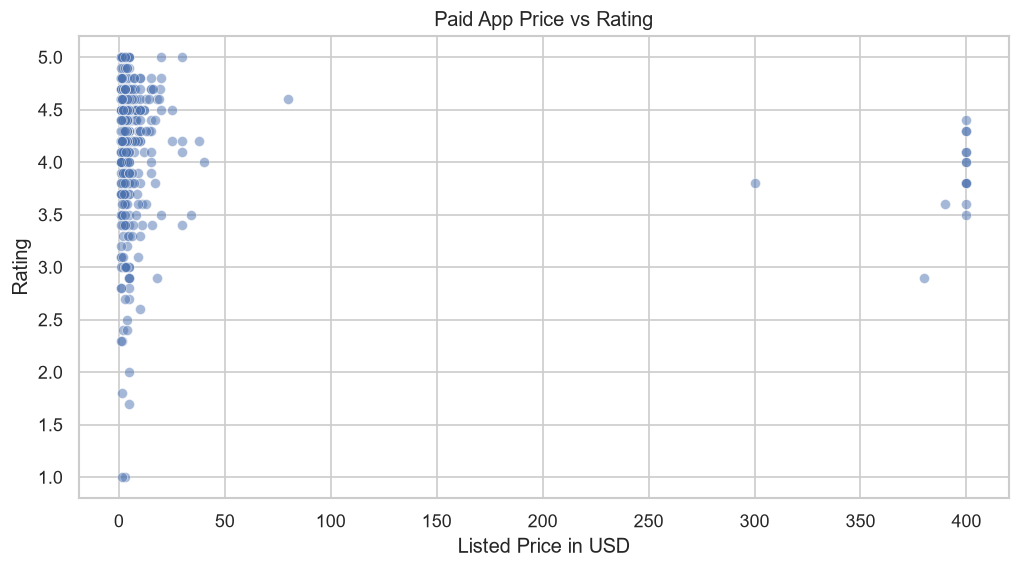

In [21]:
# Exclude free apps to make the paid-price comparison clearer.
sns.scatterplot(data=Data[Data['Price'] > 0], x='Price', y='Rating', alpha=0.5)
plt.title('Paid App Price vs Rating')
plt.xlabel('Listed Price in USD'); plt.ylabel('Rating')
plt.show()

**1. Why this chart?** A scatter plot checks whether expensive paid listings also have higher ratings.

**2. What did we find?** Paid apps have different ratings across the price range. Higher prices do not consistently come with higher ratings.

**3. Business impact:** Provide value that supports the price; this chart cannot identify the most profitable price.

## Chart 14 - Median Installs by Category
**Analysis:** Bivariate

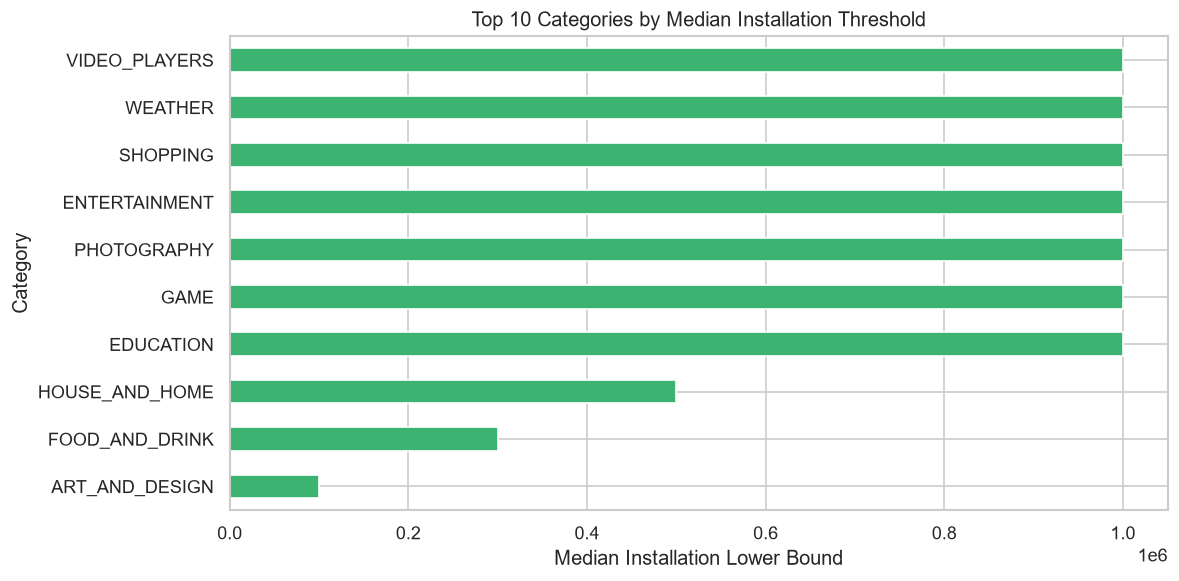

In [22]:
# Compare typical recorded install thresholds across categories.
Category_Installs = Data.groupby('Category')['Installs'].median().sort_values(ascending=False).head(10)
Category_Installs.sort_values().plot(kind='barh', color='mediumseagreen')
plt.title('Top 10 Categories by Median Installation Threshold')
plt.xlabel('Median Installation Lower Bound'); plt.ylabel('Category')
plt.tight_layout(); plt.show()

**1. Why this chart?** A median compares the typical app without being dominated by a few very large apps.

**2. What did we find?** EDUCATION is among the categories with the highest median install threshold (1,000,000). Ties are possible.

**3. Business impact:** Use category reach as a starting benchmark, not an estimate of exact market demand.

## Chart 15 - Most Reviewed Apps
**Analysis:** Bivariate

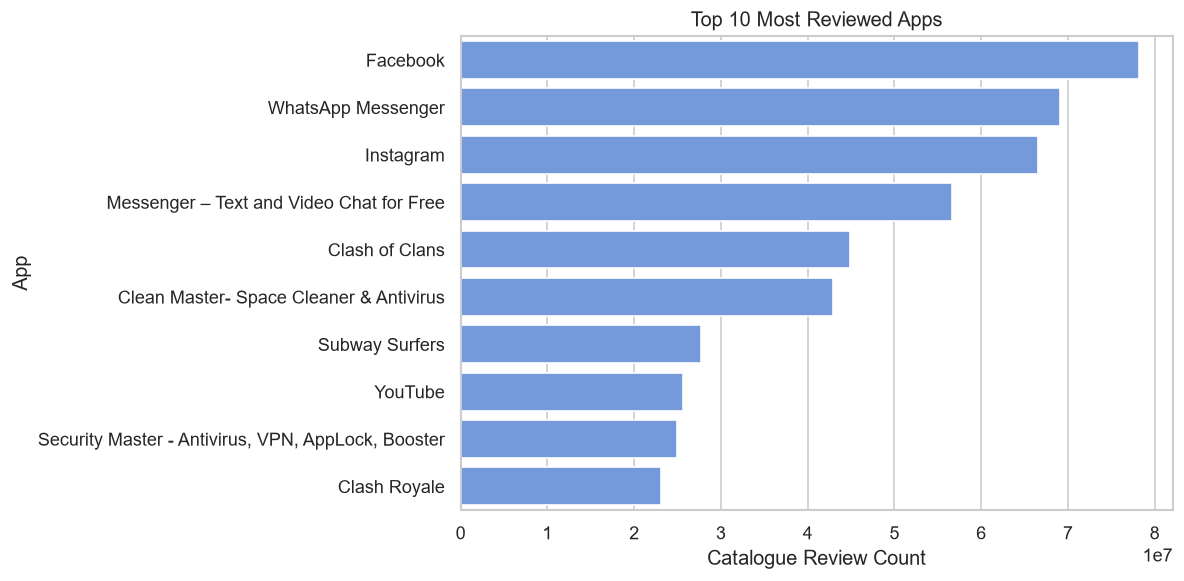

In [23]:
# Identify the ten largest catalogue review totals.
Top_Apps = Data.nlargest(10, 'Reviews')
sns.barplot(data=Top_Apps, x='Reviews', y='App', color='cornflowerblue')
plt.title('Top 10 Most Reviewed Apps')
plt.xlabel('Catalogue Review Count'); plt.ylabel('App')
plt.tight_layout(); plt.show()

**1. Why this chart?** A horizontal bar chart makes app names and review counts readable.

**2. What did we find?** Facebook has the largest review count in the cleaned catalogue (78,158,306).

**3. Business impact:** Study established apps for product ideas, but review totals do not directly measure retention or daily use.

## Chart 16 - Content Rating and App Rating
**Analysis:** Bivariate

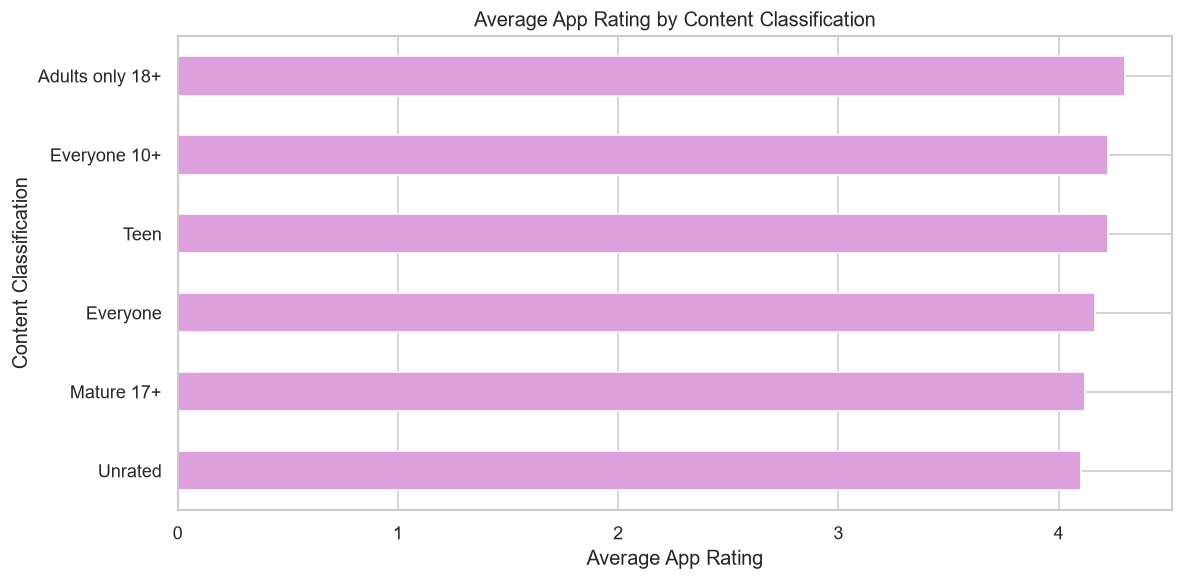

,count,mean
Content Rating,,
Adults only 18+,3,4.300000
Everyone,6618,4.166349
Everyone 10+,305,4.225902
Mature 17+,357,4.121849
Teen,912,4.225658
Unrated,1,4.100000


In [24]:
# Compare mean ratings and show the number of available ratings.
Content_Rating = Data.groupby('Content Rating')['Rating'].mean().sort_values()
Content_Rating.plot(kind='barh', color='plum')
plt.title('Average App Rating by Content Classification')
plt.xlabel('Average App Rating'); plt.ylabel('Content Classification')
plt.tight_layout(); plt.show()
display(Data.groupby('Content Rating')['Rating'].agg(['count', 'mean']))

**1. Why this chart?** Bars compare average satisfaction across intended content audiences.

**2. What did we find?** The average rating varies across classifications. Some classifications contain very few apps, so their means need caution.

**3. Business impact:** Compare satisfaction within a suitable audience group. Content classification alone does not explain product quality.

## Chart 17 - Size and Rating
**Analysis:** Bivariate

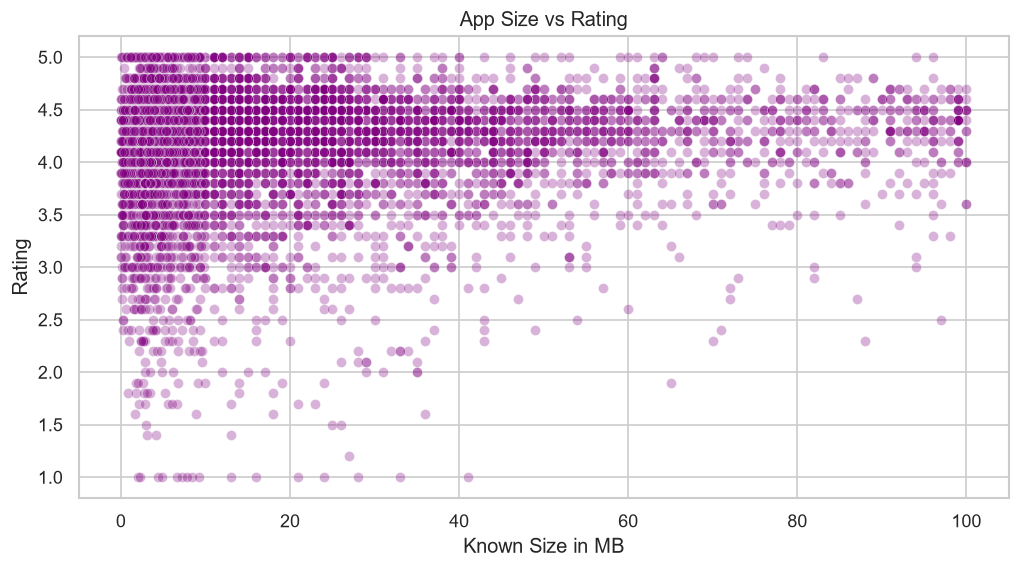

In [25]:
# Only apps with known size and rating appear in this plot.
sns.scatterplot(data=Data, x='Size_MB', y='Rating', alpha=0.3, color='purple')
plt.title('App Size vs Rating')
plt.xlabel('Known Size in MB'); plt.ylabel('Rating')
plt.show()

**1. Why this chart?** A scatter plot checks whether fixed package size relates to satisfaction.

**2. What did we find?** The Pearson size-rating correlation is 0.06.

**3. Business impact:** App size alone does not explain ratings. Review speed, usability and relevant features before changing package size.

## Chart 18 - Installs of Free and Paid Apps
**Analysis:** Bivariate

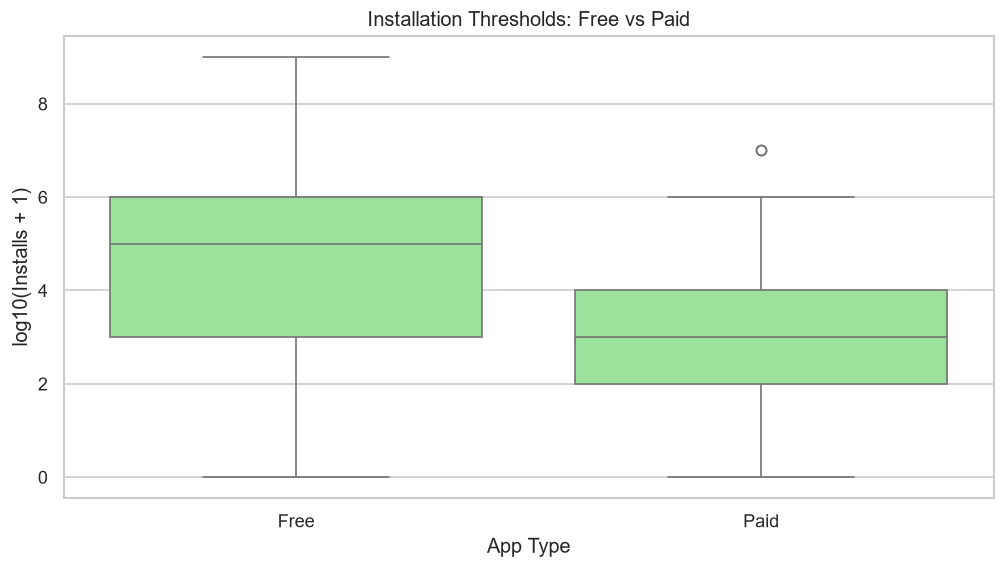

In [26]:
# Compare reach between free and paid listings.
sns.boxplot(x=Data['Type'], y=np.log10(Data['Installs'] + 1), order=['Free', 'Paid'], color='lightgreen')
plt.title('Installation Thresholds: Free vs Paid')
plt.xlabel('App Type'); plt.ylabel('log10(Installs + 1)')
plt.show()

**1. Why this chart?** A box plot compares typical reach and its spread; a log scale keeps both groups readable.

**2. What did we find?** Median install lower bounds are 100,000 for free apps and 1,000 for paid apps.

**3. Business impact:** Reach differs between pricing groups, but choosing a business model also requires cost and revenue information.

## Chart 19 - Sentiment Polarity
**Analysis:** Bivariate

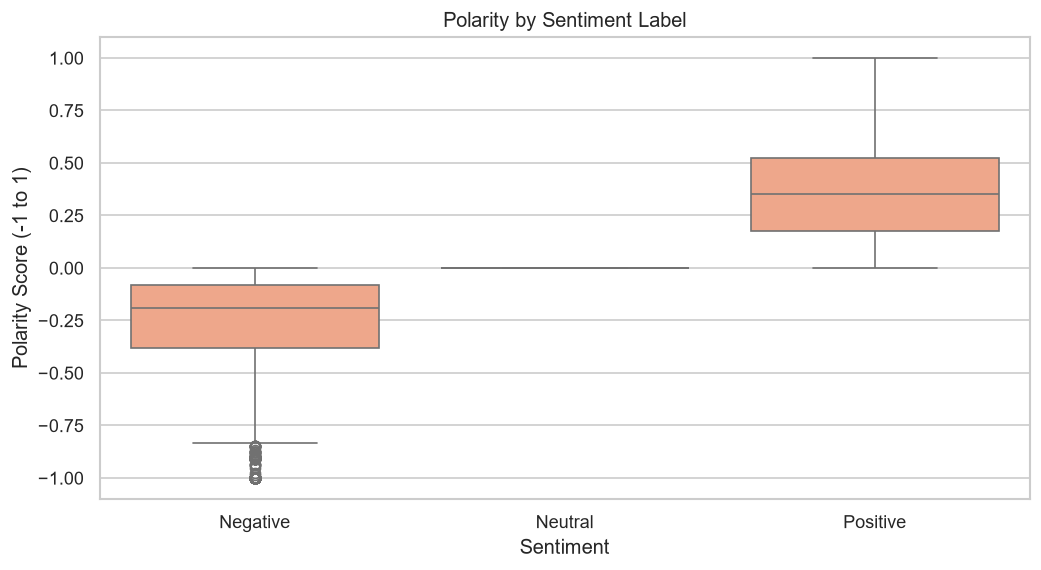

In [27]:
# Examine the scores behind the existing sentiment labels.
sns.boxplot(data=Review, x='Sentiment', y='Sentiment_Polarity',
            order=['Negative', 'Neutral', 'Positive'], color='lightsalmon')
plt.title('Polarity by Sentiment Label')
plt.xlabel('Sentiment'); plt.ylabel('Polarity Score (-1 to 1)')
plt.show()

**1. Why this chart?** A box plot compares the supplied text scores across sentiment groups.

**2. What did we find?** Negative labels have negative scores, while positive labels have positive scores. This checks the supplied labels rather than discovering an independent business relationship.

**3. Business impact:** Sentiment can organise feedback for reading. It still needs manual review to identify bugs, pricing concerns or other issues.

## Chart 20 - Correlation Heatmap
**Analysis:** Multivariate

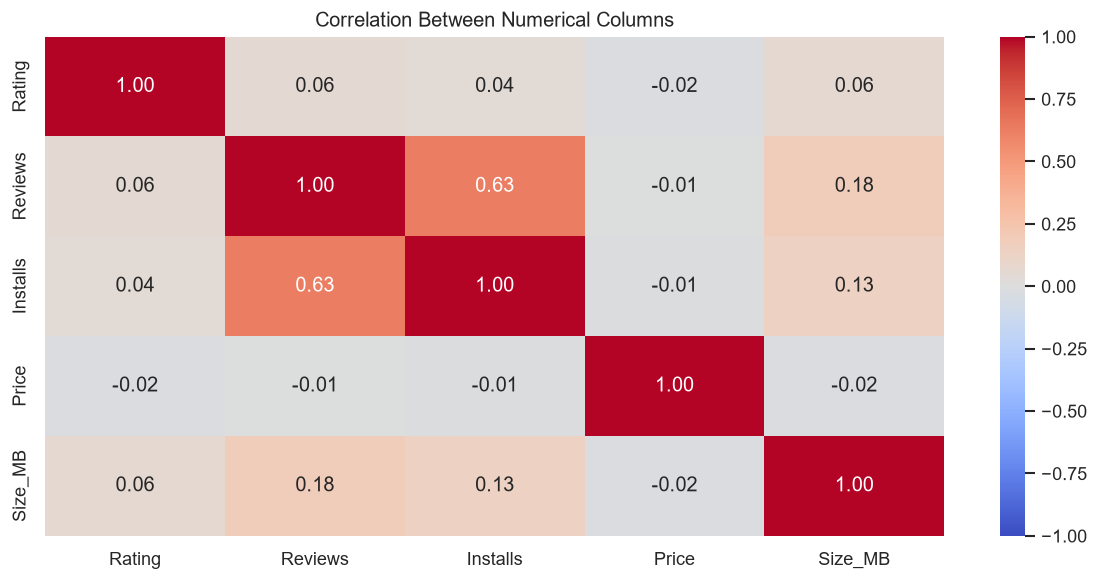

In [28]:
# Use numerical columns to calculate Pearson correlations.
Numeric_Data = Data[['Rating', 'Reviews', 'Installs', 'Price', 'Size_MB']]
sns.heatmap(Numeric_Data.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Between Numerical Columns')
plt.tight_layout(); plt.show()

**1. Why this chart?** A heatmap summarises numerical relationships in one place.

**2. What did we find?** Reviews and installs have a correlation of 0.63. Rating and installs have a correlation of 0.04. Missing values are excluded separately for each pair.

**3. Business impact:** Use the chart to understand associations. Extreme values can affect Pearson correlation, and correlation does not prove cause and effect.

# 5. Solution to the Business Objective
- **Developers:** compare ratings with similar apps and read negative feedback to decide which issues to fix.
- **Product teams:** use category and pricing comparisons as benchmarks. Do not assume one feature guarantees success.
- **Marketing teams:** review install levels, but collect conversion and acquisition-cost data before planning spending.
- **Pricing decisions:** free apps have wider typical reach in this sample, but reach alone does not tell us which model earns more money.

# Conclusion

The cleaned data contains **9,659 apps** and **29,692 usable review rows**. Most listed apps are free, and the median available rating is **4.3**. The **FAMILY** category contains the most apps in this sample. Positive reviews make up **64.0%** of the usable review sample.

Reviews and installs are positively related, while ratings alone have a much weaker relationship with installs. Developers should monitor both reach and customer satisfaction rather than relying on one measure.

### Limitations
The dataset is a historical snapshot. Install numbers are lower-bound buckets, not exact downloads or active users. Text reviews cover only selected apps and users. The project does not measure revenue, retention or growth over time. Correlation does not prove that one factor causes another.

### Learnings and Future Work
I learned to clean text-formatted numbers, handle missing data, choose charts and connect observations to business questions. Future work could use recent data, study review topics or create a simple dashboard.

### Final Check

In [29]:
# Confirm that the cleaning produced valid values and unique app names.
print('Duplicate app names:', Data['App'].duplicated().sum())
print('Ratings outside 1 to 5:', ((Data['Rating'] < 1) | (Data['Rating'] > 5)).sum())
print('Negative install values:', (Data['Installs'] < 0).sum())
print('Project completed with 20 charts.')

Duplicate app names: 0
Ratings outside 1 to 5: 0
Negative install values: 0
Project completed with 20 charts.


### Before Submission
1. Add your name and your own GitHub or Colab link.
2. Restart the Colab runtime and run all cells with both CSV files uploaded.
3. Save the notebook with the chart outputs.
4. Record your presentation using the supplied guidelines.